# SPX Directional Signal Pipeline: Analysis

End-to-end walkthrough of the pipeline:
1. Ingest OptionsDX SPX end-of-day option chain data (2010–2023)
2. Engineer daily options-flow features
3. Train a LightGBM binary classifier for next-day direction
4. Walk-forward evaluation against an always-long baseline, with calibration and VIX-regime breakdowns
5. Four charts saved to `outputs/`

In [1]:
import sys
from pathlib import Path

# Ensure project root is on the path when running from notebooks/
ROOT = Path("__file__").resolve().parent.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from pipeline.ingest import load_all
from pipeline.features import build_features
from pipeline.model import train, predict
from pipeline.backtest import run, print_summary, summarize

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")

OUTPUTS = ROOT / "outputs"
OUTPUTS.mkdir(exist_ok=True)
print(f"Output directory: {OUTPUTS.relative_to(ROOT)}")

Output directory: outputs


## 1. Ingest

Load all 168 monthly OptionsDX files recursively. Strips bracket-wrapped column names, casts to float32, and drops rows where both call and put volume are zero (illiquid deep-OTM strikes).

In [2]:
raw = load_all()

Files loaded     : 168
Date range       : 2010-01-04 → 2023-12-29
Total rows (raw) : 15,556,298
Rows dropped     : 5,404,035  (34.7% illiquid)
Rows retained    : 10,152,263
Unique expiries  : 1,808
DataFrame shape  : (10152263, 33)


## 2. Feature Engineering

Collapse ~10M strike-level rows to one row per trading date. Features capture put/call flow imbalance, term structure skew, IV skew, net delta positioning, bid-ask liquidity, and a VIX proxy from near-ATM call IV.

In [3]:
feat = build_features(raw)
print(f"Feature shape : {feat.shape}")
print(f"Date range    : {feat['date'].min().date()} → {feat['date'].max().date()}")
print(f"\nTarget split  : {feat['target'].value_counts().to_dict()}")
feat.tail(3)

Feature shape : (3491, 22)
Date range    : 2010-01-04 → 2023-12-29

Target split  : {1.0: 1893, 0.0: 1597}


,date,pc_ratio,atm_pc_ratio,near_pc_ratio,far_pc_ratio,iv_skew,net_delta,avg_c_spread_pct,avg_p_spread_pct,vix_proxy,...,pc_ratio_roll10,pc_ratio_roll20,iv_skew_roll5,iv_skew_roll10,iv_skew_roll20,net_delta_roll5,net_delta_roll10,net_delta_roll20,underlying_return_1d,target
3488,2023-12-27,1.446597,0.882394,1.232854,1.925364,0.003954,80552.648438,0.092991,0.080693,0.109640,...,1.558934,1.530498,-0.003062,-0.006374,-0.002740,-4481.864062,41941.696875,36925.081250,0.001583,1.0
3489,2023-12-28,1.450231,0.926392,1.295193,1.745771,0.002136,8634.781250,0.073938,0.065384,0.109867,...,1.562391,1.528715,-0.001647,-0.004799,-0.003411,50946.142188,25107.312500,44136.253125,0.000278,0.0
3490,2023-12-29,1.512470,1.012711,1.353287,1.912319,0.001653,31737.429688,0.106541,0.077585,0.112801,...,1.580229,1.531928,-0.001240,-0.004109,-0.002337,36030.451562,21772.699219,43053.805469,-0.002437,NaN


## 3. Model: Feature Importance

Train LightGBM on the full dataset (no train/test split) to describe which features the model relies on. This model is descriptive only and is never used for evaluation; the walk-forward section below is the out-of-sample evaluation.

In [4]:
full_model, importance = train(feat)
print(f"Top 10 features:")
print(importance.head(10).to_string(index=False))

Top 10 features:
             feature  importance
           vix_proxy 2101.875184
       iv_skew_roll5 1909.098564
             iv_skew 1836.151129
        atm_pc_ratio 1744.427464
      iv_skew_roll10 1718.366432
underlying_return_1d 1558.211299
      iv_skew_roll20 1513.858220
     pc_ratio_roll20 1484.315372
    avg_p_spread_pct 1461.471094
        far_pc_ratio 1344.531633


## 4. Walk-Forward Backtest

Expanding window: each fold trains on every trading day before the test window (at least 504 days, ~2 years), minus a 1-day purge so no training label depends on a test-period price. It then tests on the next 63 days (~1 quarter) and steps forward 63 days. 47 folds cover 2012–2023. Hyperparameters and regime cutoffs were fixed before evaluation. This cell takes several minutes; results are cached to `outputs/backtest_results.csv` on first run.

In [5]:
CACHE = OUTPUTS / "backtest_results.csv"

if CACHE.exists():
    print("Loading cached backtest results...")
    results = pd.read_csv(CACHE, parse_dates=["date"])
    results["vix_regime"] = pd.Categorical(results["vix_regime"], categories=["low", "medium", "high"])
else:
    print("Running walk-forward backtest (this will take a few minutes)...")
    results, _ = run(feat)
    results.to_csv(CACHE, index=False)
    print(f"Results cached to {CACHE.relative_to(ROOT)}")

metrics = summarize(results)
print_summary(metrics)

Running walk-forward backtest (this will take a few minutes)...


  Fold   1  test start=2012-01-27  win=62%  [0%]


  Fold   2  test start=2012-04-30  win=57%  [2%]


  Fold   3  test start=2012-07-30  win=51%  [4%]


  Fold   4  test start=2012-10-29  win=41%  [6%]


...

  Fold  42  test start=2022-05-25  win=51%  [87%]


  Fold  43  test start=2022-08-24  win=44%  [89%]


  Fold  44  test start=2022-11-21  win=44%  [91%]


  Fold  45  test start=2023-02-23  win=54%  [93%]
  Fold  46  test start=2023-05-24  win=56%  [95%]


  Fold  47  test start=2023-08-24  win=65%  [97%]
Results cached to outputs/backtest_results.csv

=== Overall ===  n=2961
                     model   always long
  Win rate           51.3%         53.7%
  Sharpe              0.80          0.71
  Max drawdown      -42.9%        -38.3%
  Summed return     159.6%        141.2%
  Compounded        316.4%        246.1%

=== By VIX Regime ===

[LOW VIX]  n=1820
                     model   always long
  Win rate           50.3%         53.6%
  Sharpe              0.15          0.57
  Max drawdown      -31.9%        -15.1%
  Summed return      11.4%         42.1%
  Compounded          7.9%         46.7%

[MEDIUM VIX]  n=915
                     model   always long
  Win rate           51.9%         53.7%
  Sharpe              1.04          0.69
  Max drawdown      -26.8%        -34.4%
  Summed return      73.2%         48.4%
  Compounded         94.1%         51.4%

[HIGH VIX]  n=173
                     model   always long
  Win rate       

## Chart 1 — P/C Ratio vs SPX Price

Daily put/call volume ratio overlaid with SPX price. Elevated P/C ratios often coincide with fear and market bottoms — this chart shows how the signal tracks market stress.

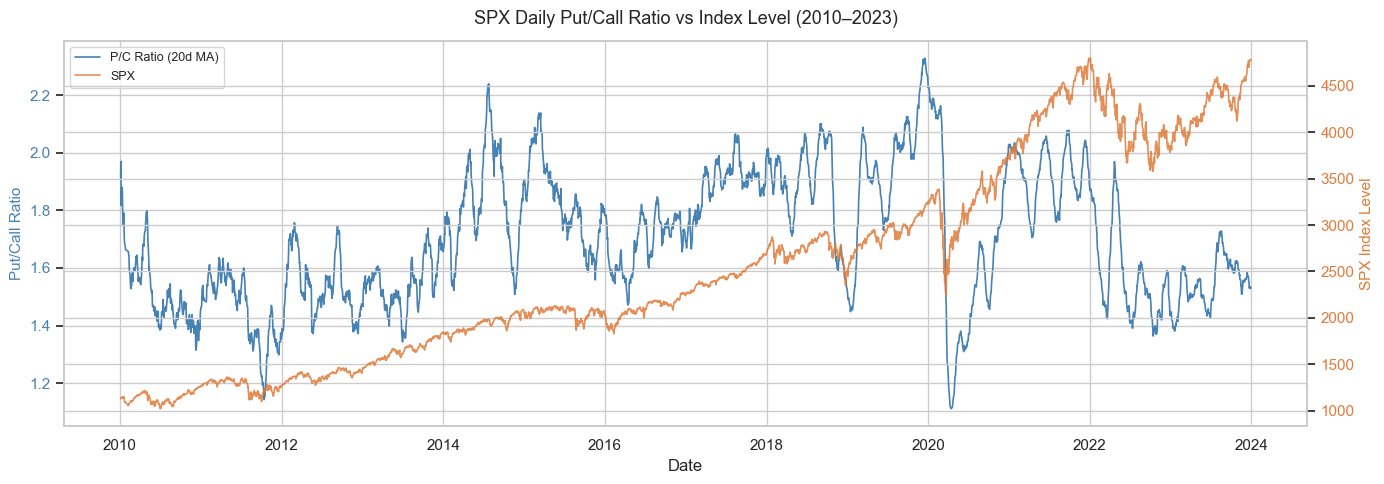

Saved: pc_ratio_vs_spx.png


In [6]:
# Get daily SPX price directly from the raw ingest (avoids external dependency)
spx = raw.groupby("QUOTE_DATE")["UNDERLYING_LAST"].first().reset_index()
spx.columns = ["date", "spx"]

pc_daily = feat[["date", "pc_ratio"]].copy()
chart_df = pc_daily.merge(spx, on="date", how="inner")

# Smooth P/C ratio with 20-day rolling mean for readability
chart_df["pc_smooth"] = chart_df["pc_ratio"].rolling(20, min_periods=1).mean()

fig, ax1 = plt.subplots(figsize=(14, 5))

ax1.plot(chart_df["date"], chart_df["pc_smooth"], color="steelblue", lw=1.2, label="P/C Ratio (20d MA)")
ax1.set_ylabel("Put/Call Ratio", color="steelblue", fontsize=11)
ax1.tick_params(axis="y", labelcolor="steelblue")
ax1.set_xlabel("Date")

ax2 = ax1.twinx()
ax2.plot(chart_df["date"], chart_df["spx"], color="#e07b3a", lw=1.2, alpha=0.85, label="SPX")
ax2.set_ylabel("SPX Index Level", color="#e07b3a", fontsize=11)
ax2.tick_params(axis="y", labelcolor="#e07b3a")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", fontsize=9)

plt.title("SPX Daily Put/Call Ratio vs Index Level (2010–2023)", fontsize=13, pad=12)
fig.tight_layout()
fig.savefig(OUTPUTS / "pc_ratio_vs_spx.png", dpi=150)
plt.show()
print("Saved: pc_ratio_vs_spx.png")

## Chart 2: Walk-Forward Cumulative P&L

Cumulative summed daily return of the signal (long SPX when the model predicts up, short when it predicts down) across all 47 out-of-sample test windows, shown against simply holding SPX long over the same days. No transaction costs.

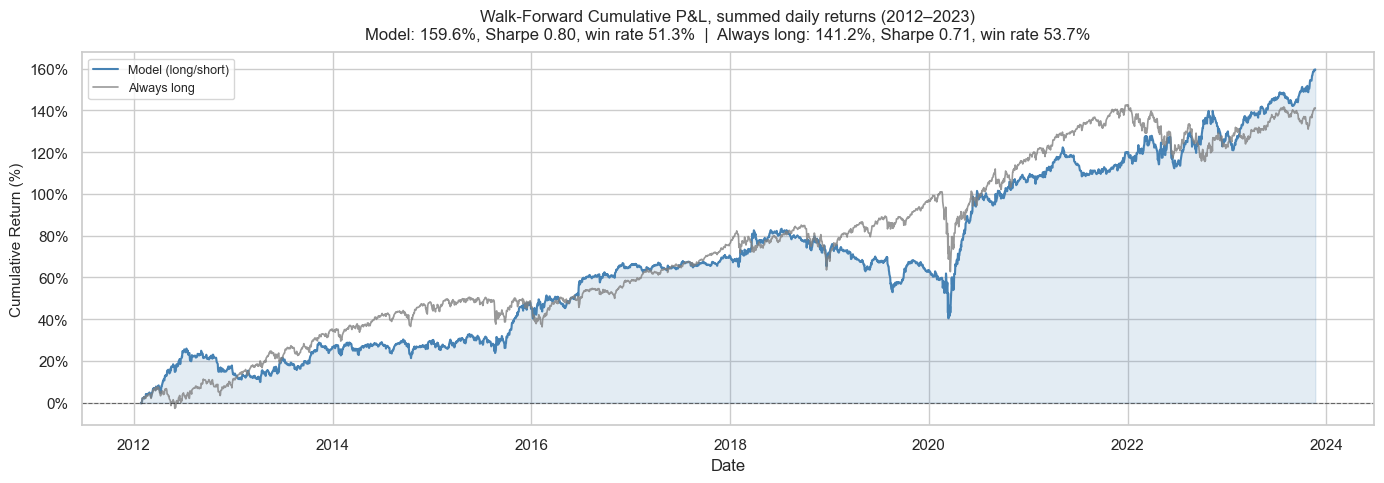

Saved: walkforward_pnl.png


In [7]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(results["date"], results["cumulative_pnl"] * 100, color="steelblue", lw=1.5, label="Model (long/short)")
ax.plot(results["date"], results["fwd_return"].cumsum() * 100, color="grey", lw=1.2, alpha=0.8, label="Always long")
ax.axhline(0, color="black", lw=0.8, linestyle="--", alpha=0.5)
ax.fill_between(
    results["date"],
    results["cumulative_pnl"] * 100,
    0,
    where=results["cumulative_pnl"] >= 0,
    alpha=0.15,
    color="steelblue",
)
ax.fill_between(
    results["date"],
    results["cumulative_pnl"] * 100,
    0,
    where=results["cumulative_pnl"] < 0,
    alpha=0.15,
    color="tomato",
)

total_ret = results["cumulative_pnl"].iloc[-1] * 100
sharpe = metrics["overall"]["sharpe"]
win_rate = metrics["overall"]["win_rate"]
base = metrics["baseline"]["overall"]
ax.set_title(
    f"Walk-Forward Cumulative P&L, summed daily returns (2012–2023)\n"
    f"Model: {total_ret:.1f}%, Sharpe {sharpe:.2f}, win rate {win_rate:.1%}  |  "
    f"Always long: {base['total_return'] * 100:.1f}%, Sharpe {base['sharpe']:.2f}, win rate {base['win_rate']:.1%}",
    fontsize=12, pad=10
)
ax.set_ylabel("Cumulative Return (%)", fontsize=11)
ax.set_xlabel("Date")
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.0f%%"))
ax.legend(loc="upper left", fontsize=9)

fig.tight_layout()
fig.savefig(OUTPUTS / "walkforward_pnl.png", dpi=150)
plt.show()
print("Saved: walkforward_pnl.png")

## Chart 3: Win Rate by VIX Regime

Directional accuracy split across three volatility regimes based on the VIX proxy (ATM call IV for 25–35 DTE options), with the always-long win rate for the same days marked. Days with no VIX proxy (no liquid ATM option in the 25–35 DTE window) are excluded.

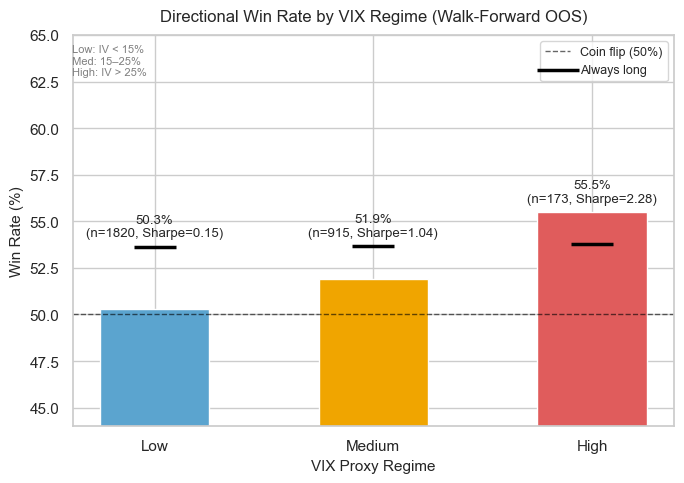

Saved: winrate_by_regime.png


In [8]:
regime_rows = []
for regime in ["low", "medium", "high"]:
    m = metrics["by_regime"][regime]
    if m and m["n_days"] > 0:
        regime_rows.append({
            "regime": regime.capitalize(),
            "win_rate": m["win_rate"] * 100,
            "n_days": m["n_days"],
            "sharpe": m["sharpe"],
            "baseline_win_rate": metrics["baseline"]["by_regime"][regime]["win_rate"] * 100,
        })
regime_df = pd.DataFrame(regime_rows)

fig, ax = plt.subplots(figsize=(7, 5))
colors = ["#5ba4cf", "#f0a500", "#e05c5c"]
bars = ax.bar(regime_df["regime"], regime_df["win_rate"], color=colors, width=0.5, edgecolor="white")

ax.axhline(50, color="black", lw=1.0, linestyle="--", alpha=0.6, label="Coin flip (50%)")
ax.scatter(regime_df["regime"], regime_df["baseline_win_rate"], marker="_", s=900, lw=2.5,
           color="black", zorder=3, label="Always long")

for bar, row in zip(bars, regime_df.itertuples()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        max(bar.get_height(), row.baseline_win_rate) + 0.4,
        f"{row.win_rate:.1f}%\n(n={row.n_days}, Sharpe={row.sharpe:.2f})",
        ha="center", va="bottom", fontsize=9.5
    )

ax.set_ylim(44, 65)
ax.set_ylabel("Win Rate (%)", fontsize=11)
ax.set_xlabel("VIX Proxy Regime", fontsize=11)
ax.set_title("Directional Win Rate by VIX Regime (Walk-Forward OOS)", fontsize=12, pad=10)
ax.legend(fontsize=9)

# Annotate regime boundaries
ax.text(-0.38, 64.5, "Low: IV < 15%\nMed: 15–25%\nHigh: IV > 25%", fontsize=8, color="grey", va="top")

fig.tight_layout()
fig.savefig(OUTPUTS / "winrate_by_regime.png", dpi=150)
plt.show()
print("Saved: winrate_by_regime.png")

## Chart 4: Feature Importance (Top 15)

LightGBM gain-based feature importances from the full-sample descriptive model. Under gain importance the VIX proxy and IV skew (with its rolling variants) rank highest, followed by the ATM put/call ratio. Importance describes what the model uses, not whether those features predict out of sample.

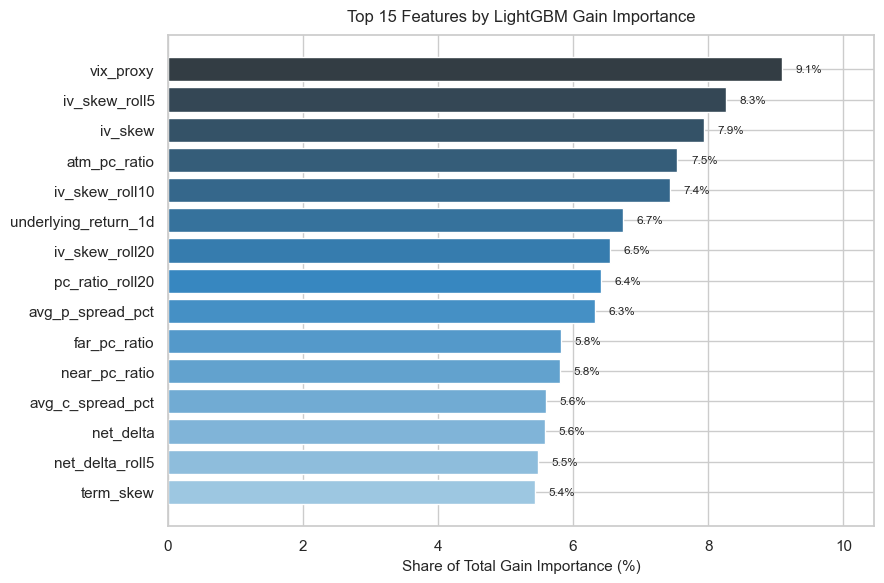

Saved: feature_importance.png


In [9]:
top15 = importance.head(15).copy()
top15["importance_pct"] = top15["importance"] / top15["importance"].sum() * 100

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(
    top15["feature"][::-1],
    top15["importance_pct"][::-1],
    color=sns.color_palette("Blues_d", len(top15)),
    edgecolor="white",
)

for bar, val in zip(bars, top15["importance_pct"][::-1]):
    ax.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height() / 2,
            f"{val:.1f}%", va="center", fontsize=8.5)

ax.set_xlabel("Share of Total Gain Importance (%)", fontsize=11)
ax.set_title("Top 15 Features by LightGBM Gain Importance", fontsize=12, pad=10)
ax.set_xlim(0, top15["importance_pct"].max() * 1.15)

fig.tight_layout()
fig.savefig(OUTPUTS / "feature_importance.png", dpi=150)
plt.show()
print("Saved: feature_importance.png")

## Regime concentration and calibration

High-VIX days are not spread evenly through the sample, so the high-regime figures rest on a few market episodes. The calibration table compares predicted up-probabilities with observed up-rates.

In [10]:
high = results[results["vix_regime"] == "high"]
print("High-VIX OOS days by year:")
print(high["date"].dt.year.value_counts().sort_index().to_string())

cal = metrics["calibration"]
print(f"\nBrier score: {cal['brier']:.4f}  (coin flip 0.25, constant at OOS up-rate {cal['brier_base_rate']:.4f})")
cal["table"]

High-VIX OOS days by year:
date
2015     3
2016     1
2018     7
2019     6
2020    81
2021     2
2022    73

Brier score: 0.3080  (coin flip 0.25, constant at OOS up-rate 0.2486)


,bin,mean_predicted,observed_up_rate,n_days
0,"(-0.001, 0.1]",0.057453,0.487603,121
1,"(0.1, 0.2]",0.153667,0.553191,235
2,"(0.2, 0.3]",0.250641,0.509728,257
3,"(0.3, 0.4]",0.350080,0.507375,339
4,"(0.4, 0.5]",0.452753,0.557522,339
5,"(0.5, 0.6]",0.547252,0.550725,345
6,"(0.6, 0.7]",0.646720,0.515707,382
7,"(0.7, 0.8]",0.747291,0.542857,350
8,"(0.8, 0.9]",0.848184,0.554622,357
9,"(0.9, 1.0]",0.944961,0.567797,236


## Summary

In [11]:
o, b = metrics["overall"], metrics["baseline"]["overall"]
rows = [
    ("OOS test days (walk-forward)", f"{o['n_days']:,}", ""),
    ("Win rate", f"{o['win_rate']:.1%}", f"{b['win_rate']:.1%}"),
    ("Sharpe (annualised, no costs)", f"{o['sharpe']:.2f}", f"{b['sharpe']:.2f}"),
    ("Summed return", f"{o['total_return']:.1%}", f"{b['total_return']:.1%}"),
    ("Max drawdown (summed)", f"{o['max_drawdown']:.1%}", f"{b['max_drawdown']:.1%}"),
]
for r in ["low", "medium", "high"]:
    m, mb = metrics["by_regime"][r], metrics["baseline"]["by_regime"][r]
    rows.append((f"{r.capitalize()} VIX win rate / Sharpe (n={m['n_days']})",
                 f"{m['win_rate']:.1%} / {m['sharpe']:.2f}", f"{mb['win_rate']:.1%} / {mb['sharpe']:.2f}"))
rows.append(("Days with no VIX proxy", str(metrics["n_no_regime"]), ""))
rows.append(("Brier score", f"{metrics['calibration']['brier']:.4f}", ""))
pd.DataFrame(rows, columns=["", "Model", "Always long"]).set_index("")

,Model,Always long
,,
OOS test days (walk-forward),"2,961",
Win rate,51.3%,53.7%
"Sharpe (annualised, no costs)",0.80,0.71
Summed return,159.6%,141.2%
Max drawdown (summed),-42.9%,-38.3%
Low VIX win rate / Sharpe (n=1820),50.3% / 0.15,53.6% / 0.57
Medium VIX win rate / Sharpe (n=915),51.9% / 1.04,53.7% / 0.69
High VIX win rate / Sharpe (n=173),55.5% / 2.28,53.8% / 1.66
Days with no VIX proxy,53,


Overall, the model's win rate is below the always-long baseline while its Sharpe is modestly higher. Relative to the baseline it underperforms in the low-VIX regime and outperforms in the medium- and high-VIX regimes; the high-VIX figures rest on 173 days, most of them in 2020 and 2022.

Predicted probabilities are poorly calibrated: the Brier score is worse than a constant forecast, and the observed up-rate barely changes across probability bins. Only the direction of each prediction (threshold 0.5) is used.

These results are historical and descriptive. They demonstrate the evaluation pipeline and are not evidence of future trading performance or investment advice.